# Credit Card Fraud Exploratory Data Analysis

This notebook explores patterns in credit card transaction data that may be associated with fraudulent transactions. The goal is to understand the dataset through exploratory data analysis before considering any predictive modeling.

## AI System Used

OpenAI ChatGPT — GPT-6.1 Sol Medium

## Prompt Documentation Note

The prompts presented below were prepared with AI assistance to describe
the analysis discussed in Korean. They are not a verbatim conversation log.

## Presented Prompt

I have a credit card transaction dataset and want to perform exploratory data analysis before building any machine learning model. What should I check first to understand the structure, variables, data types, and possible missing values in the dataset?


## Data Source and Variables

The dataset used in this analysis is `card_transdata.csv`, downloaded
from the MAT311 course materials on Brightspace. The supplied file
contains 999 transactions and eight columns.

| Variable | Description |
|---|---|
| distance_from_home | Distance from the customer's home to the transaction location |
| distance_from_last_transaction | Distance between the previous and current transaction locations |
| ratio_to_median_purchase_price | Transaction purchase amount divided by the median purchase price |
| repeat_retailer | Whether the transaction involved a previously used retailer |
| used_chip | Whether a credit card chip was used |
| used_pin_number | Whether a PIN was used |
| online_order | Whether the transaction was an online order |
| fraud | Whether the transaction was fraudulent |

For the binary variables, 0 means no and 1 means yes. In the fraud
column, 0 represents a non-fraudulent transaction and 1 represents
a fraudulent transaction.

Distance units and the exact calculation of the reference median
purchase price are not specified in the supplied materials.


In [1]:
# Import tools for checking the Python environment and file paths
import sys
from pathlib import Path

# Import libraries for data analysis and visualization
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Verify the active Python environment and locate the dataset
print("Python version:", sys.version)
print("Python executable:", sys.executable)
print("Working directory:", Path.cwd())
print("CSV found:", Path("card_transdata.csv").is_file())

# Record installed library versions for reproducibility
print("pandas:", pd.__version__)
print("matplotlib:", plt.matplotlib.__version__)
print("seaborn:", sns.__version__)


Python version: 3.13.15 (tags/v3.13.15:4061bc4, Aug  5 2026, 13:05:39) [MSC v.1944 64 bit (AMD64)]
Python executable: c:\Users\sword\AppData\Local\Programs\Python\Python313\python.exe
Working directory: x:\26 Fall\MAT 311\10th week\MAT311_Credit_Card_Fraud
CSV found: True
pandas: 3.0.6
matplotlib: 3.11.2
seaborn: 0.13.2


## Load and Inspect the Dataset

### Presented Prompt

I have the CSV in the same folder as my notebook. Can you help me load it with pandas and check the first few rows, the number of rows and columns, and the data types? Please explain each step.


In [2]:
# Read the CSV from the notebook working directory
df = pd.read_csv("card_transdata.csv")

# Preview transactions and inspect dimensions, types, and non-null counts
display(df.head())
print("Rows and columns:", df.shape)
df.info()


,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0
1,10.829943,0.175592,1.294219,1.0,NaN,0.0,0.0,0
2,5.091079,NaN,0.427715,1.0,0.0,0.0,1.0,0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0


Rows and columns: (999, 8)
<class 'pandas.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 8 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   distance_from_home              999 non-null    float64
 1   distance_from_last_transaction  996 non-null    float64
 2   ratio_to_median_purchase_price  997 non-null    float64
 3   repeat_retailer                 992 non-null    float64
 4   used_chip                       995 non-null    float64
 5   used_pin_number                 997 non-null    float64
 6   online_order                    995 non-null    float64
 7   fraud                           999 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 62.6 KB


## Review Summary Statistics

### Presented Prompt

How can I check the basic statistics for these columns? Help me compare the mean, median, and maximum values, especially for the distances and purchase price ratio.


In [3]:
# Review numeric summaries, including the median and extreme values
display(df.describe())


,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
count,999.000000,996.000000,997.000000,992.000000,995.000000,997.000000,995.000000,999.000000
mean,26.876607,5.437319,1.655069,0.892137,0.313568,0.117352,0.673367,0.079079
std,63.899697,35.668094,2.351386,0.310364,0.464176,0.322001,0.469218,0.269997
min,0.104184,0.001448,0.016933,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.990543,0.306441,0.468123,1.000000,0.000000,0.000000,0.000000,0.000000
50%,10.340321,0.958539,0.955504,1.000000,0.000000,0.000000,1.000000,0.000000
75%,25.393952,3.137259,1.922025,1.000000,1.000000,0.000000,1.000000,0.000000
max,965.910612,990.070315,36.074366,1.000000,1.000000,1.000000,1.000000,1.000000


## Check Missing Values

### Presented Prompt

Can you show me how to count the missing values in each column and check how many rows have at least one missing value? I also want to see what percentage of the dataset those rows represent.


In [4]:
# Missing values in each column
display(df.isna().sum())

# Count each row with missing data once and divide by all original rows
missing_rows = df.isna().any(axis=1).sum()

print("Rows with missing values:", missing_rows)
print(f"Percentage of all rows: {missing_rows / len(df):.2%}")

distance_from_home                0
distance_from_last_transaction    3
ratio_to_median_purchase_price    2
repeat_retailer                   7
used_chip                         4
used_pin_number                   2
online_order                      4
fraud                             0
dtype: int64

Rows with missing values: 22
Percentage of all rows: 2.20%


## Remove Incomplete Rows

### Presented Prompt

I want to follow the reference analysis by removing rows with missing values. Can you keep the original data and save the cleaned data separately? Show the number of rows removed and check that no missing values remain.


In [5]:
# Count incomplete rows once, regardless of how many values are missing
missing_rows = df.isna().any(axis=1).sum()

print("Rows with missing values:", missing_rows)
print(f"Percentage removed: {missing_rows / len(df):.2%}")

# Create a separate complete-case dataset while preserving the original
df_clean = df.dropna().copy()

# Verify the cleaned dimensions and confirm that no missing values remain
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)
print("Remaining missing values:", df_clean.isna().sum().sum())


Rows with missing values: 22
Percentage removed: 2.20%
Original shape: (999, 8)
Cleaned shape: (977, 8)
Remaining missing values: 0


### Observations

Rows with missing values account for 2.20% of the original dataset. Complete-case analysis is used to follow the reference analysis while preserving the original DataFrame. A small removal percentage alone does not guarantee that exclusion is unbiased.


## Compare Normal and Fraudulent Transactions

### Presented Prompt

Using df_clean, can you help me compare the counts and percentages of normal and fraudulent transactions? Please show a table and a bar chart, and add comments explaining the main steps.


,Count,Percentage
fraud,,
Non-fraud,901,92.221085
Fraud,76,7.778915


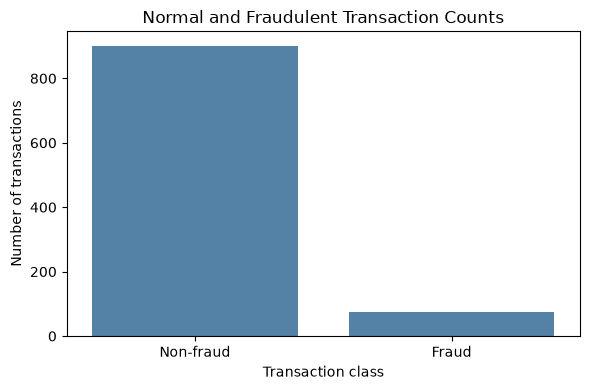

In [6]:
# Count fraud labels (0 = non-fraud, 1 = fraud) and calculate percentages
# Use all cleaned transactions as the percentage denominator
fraud_counts = df_clean["fraud"].value_counts().sort_index()

display(pd.DataFrame({
    "Count": fraud_counts,
    "Percentage": fraud_counts / len(df_clean) * 100
}).rename(index={0: "Non-fraud", 1: "Fraud"}))

# Plot the number of transactions in each class
plt.figure(figsize=(6, 4))

sns.countplot(data=df_clean, x="fraud", order=[0, 1], color="steelblue")

plt.xticks([0, 1], ["Non-fraud", "Fraud"])
plt.xlabel("Transaction class")
plt.ylabel("Number of transactions")
plt.title("Normal and Fraudulent Transaction Counts")
plt.tight_layout()
plt.show()

### Observations

The cleaned dataset contains 901 non-fraudulent transactions and 76 fraudulent transactions. Fraud accounts for approximately 7.78% of the cleaned data, so the two classes are imbalanced.


## Explore Transaction Characteristics

### Presented Prompt

Can you help me check how many transactions used a PIN, involved a repeat retailer, or were online orders? Use df_clean, show count plots with clear labels, and include the exact counts.



PIN Usage


,Count
No PIN,860
PIN used,117



Repeat Retailers


,Count
New retailer,103
Repeat retailer,874



Online Orders


,Count
Not online,319
Online,658


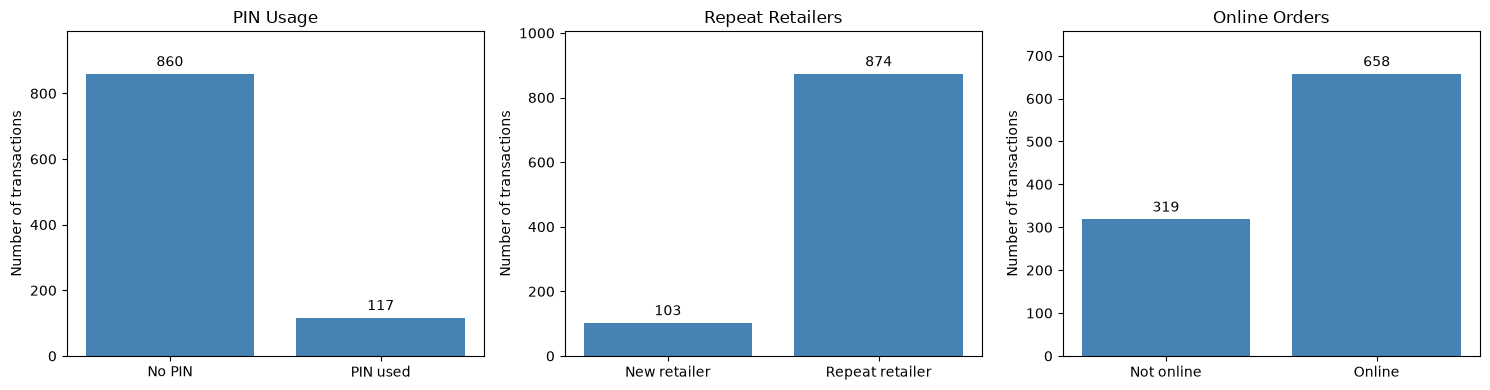

In [7]:
# Define binary features and descriptive category labels
features = [
    ("used_pin_number", "PIN Usage", ["No PIN", "PIN used"]),
    ("repeat_retailer", "Repeat Retailers", ["New retailer", "Repeat retailer"]),
    ("online_order", "Online Orders", ["Not online", "Online"])
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (column, title, labels) in zip(axes, features):
    # Count transactions in a fixed category order
    counts = df_clean[column].value_counts().reindex([0, 1], fill_value=0)

    # Display a table with descriptive labels
    summary = pd.DataFrame({"Count": counts.to_numpy()}, index=labels)
    print(f"\n{title}")
    display(summary)

    # Plot the calculated counts directly
    bars = ax.bar(labels, counts.to_numpy(), color="steelblue")

    # Show exact counts above the bars
    ax.bar_label(bars, padding=3)
    ax.set_ylim(0, counts.max() * 1.15)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Number of transactions")

plt.tight_layout()
plt.show()

### Observations

Of the 977 cleaned transactions, 117 used a PIN, 874 involved a repeat retailer, and 658 were online orders. These counts describe the overall transaction mix rather than group-specific fraud rates.


## Explore Purchase Ratios and Distances

### Presented Prompt

Can you help me make histograms of the purchase price ratio and distance
from home? Use df_clean with 30 bins and keep all observations, including
extreme values. Add comments explaining the main steps.


Purchase Price Ratio: 977 transactions plotted
Distance from Home: 977 transactions plotted


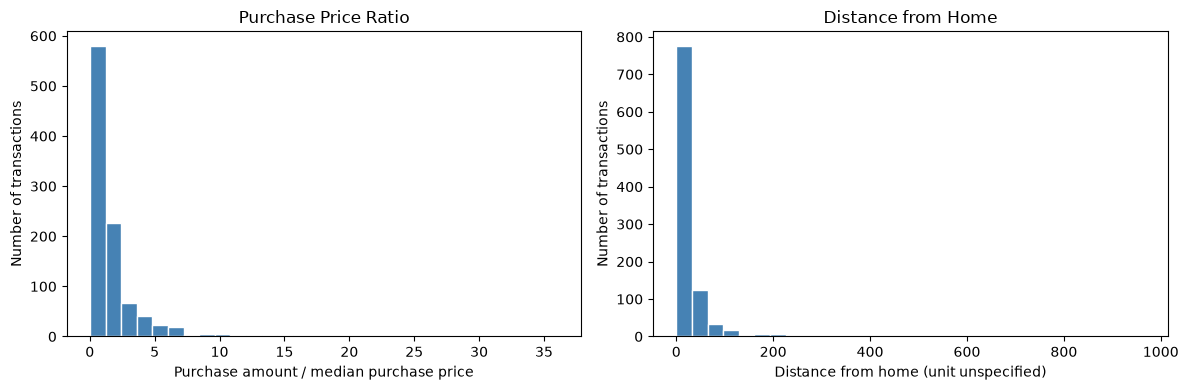

In [8]:
# Define numeric columns, chart titles, and axis labels
numeric_features = [
    (
        "ratio_to_median_purchase_price",
        "Purchase Price Ratio",
        "Purchase amount / median purchase price"
    ),
    (
        "distance_from_home",
        "Distance from Home",
        "Distance from home (unit unspecified)"
    )
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (column, title, label) in zip(axes, numeric_features):
    # Divide the full data range into 30 bins without removing extreme values
    counts, edges, bars = ax.hist(
        df_clean[column].to_numpy(),
        bins=30,
        color="steelblue",
        edgecolor="white"
    )

    # Verify that every cleaned transaction is included
    print(f"{title}: {int(counts.sum())} transactions plotted")

    ax.set_title(title)
    ax.set_xlabel(label)
    ax.set_ylabel("Number of transactions")

plt.tight_layout()
plt.show()

### Observations

Both distributions are right-skewed. Most transactions have relatively
small purchase price ratios and short distances from home, while a few
have much larger values.

All 977 cleaned transactions are included in each histogram. Extreme
values are retained because a large value alone does not establish
that a transaction is incorrect or fraudulent.


## Compare Transaction Characteristics with Fraud

### Presented Prompt

Can you help me compare PIN usage, chip usage, and online orders with
fraud? Show counts and percentages within each group using tables and
charts. Add comments explaining the percentage denominator.



PIN Usage: Counts


,Non-fraud,Fraud
No PIN,784,76
PIN used,117,0


PIN Usage: Within-group percentages


,Non-fraud,Fraud
No PIN,91.16,8.84
PIN used,100.00,0.00


Total transactions: 977
Percentage row totals: [100.0, 100.0]


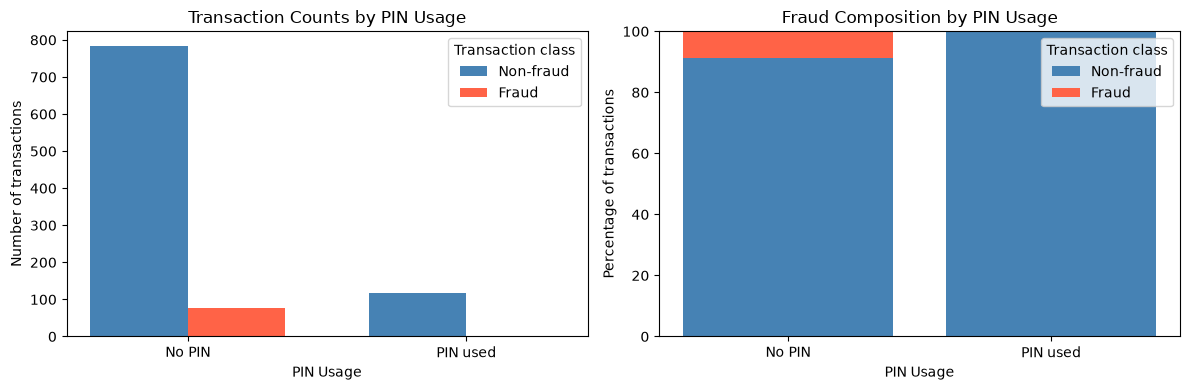


Chip Usage: Counts


,Non-fraud,Fraud
No chip,610,63
Chip used,291,13


Chip Usage: Within-group percentages


,Non-fraud,Fraud
No chip,90.64,9.36
Chip used,95.72,4.28


Total transactions: 977
Percentage row totals: [100.0, 100.0]


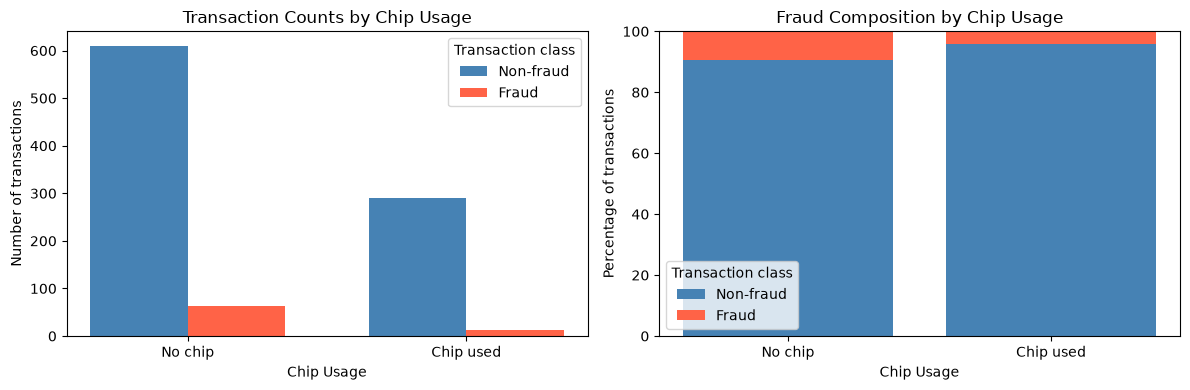


Online Orders: Counts


,Non-fraud,Fraud
Not online,317,2
Online,584,74


Online Orders: Within-group percentages


,Non-fraud,Fraud
Not online,99.37,0.63
Online,88.75,11.25


Total transactions: 977
Percentage row totals: [100.0, 100.0]


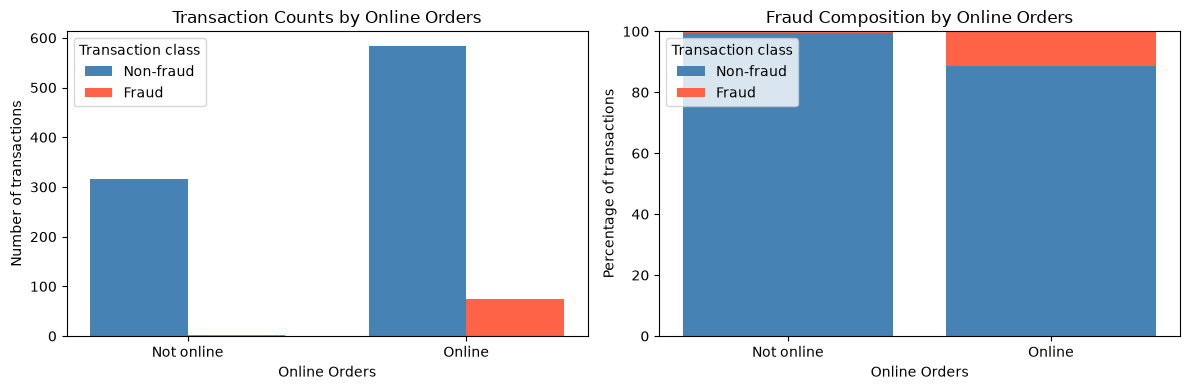

In [9]:
# Define the features and their category labels
comparisons = [
    ("used_pin_number", "PIN Usage", ["No PIN", "PIN used"]),
    ("used_chip", "Chip Usage", ["No chip", "Chip used"]),
    ("online_order", "Online Orders", ["Not online", "Online"])
]

for column, title, labels in comparisons:
    # Count normal and fraudulent transactions in each group
    counts = pd.crosstab(
        df_clean[column], df_clean["fraud"]
    ).reindex(index=[0, 1], columns=[0, 1], fill_value=0)

    # Use each group's total as the denominator
    percentages = counts.div(counts.sum(axis=1), axis=0) * 100

    counts.index = labels
    counts.columns = ["Non-fraud", "Fraud"]
    percentages.index = labels
    percentages.columns = counts.columns

    print(f"\n{title}: Counts")
    display(counts)

    print(f"{title}: Within-group percentages")
    display(percentages.round(2))

    # Verify that all transactions are counted and each row totals 100%
    print("Total transactions:", int(counts.to_numpy().sum()))
    print("Percentage row totals:", percentages.sum(axis=1).round(2).tolist())

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    positions = [0, 1]
    width = 0.35

    # Draw grouped bars for absolute transaction counts
    axes[0].bar(
        [x - width / 2 for x in positions],
        counts["Non-fraud"].to_numpy(),
        width=width, label="Non-fraud", color="steelblue"
    )
    axes[0].bar(
        [x + width / 2 for x in positions],
        counts["Fraud"].to_numpy(),
        width=width, label="Fraud", color="tomato"
    )
    axes[0].set_title(f"Transaction Counts by {title}")
    axes[0].set_ylabel("Number of transactions")

    # Stack percentages so each group's bar totals 100%
    axes[1].bar(
        positions, percentages["Non-fraud"].to_numpy(),
        label="Non-fraud", color="steelblue"
    )
    axes[1].bar(
        positions, percentages["Fraud"].to_numpy(),
        bottom=percentages["Non-fraud"].to_numpy(),
        label="Fraud", color="tomato"
    )
    axes[1].set_title(f"Fraud Composition by {title}")
    axes[1].set_ylabel("Percentage of transactions")
    axes[1].set_ylim(0, 100)

    for ax in axes:
        ax.set_xticks(positions)
        ax.set_xticklabels(labels)
        ax.set_xlabel(title)
        ax.legend(title="Transaction class")

    plt.tight_layout()
    plt.show()

### Observations

The fraud rate was 8.84% for transactions without a PIN. No fraud was
observed among the 117 transactions using a PIN, but this does not
establish that PIN usage prevents all fraud.

Transactions using a chip had a lower fraud rate (4.28%) than those
without a chip (9.36%). Online orders had a higher fraud rate (11.25%)
than transactions that were not online (0.63%).

Each percentage uses its own group's total as the denominator, allowing
comparison between groups of different sizes. These results describe
associations in this dataset and do not establish causation.


## Explore Distance and Purchase Ratios by Fraud Status

### Presented Prompt

Can you help me make two scatter plots comparing the purchase price ratio
with distance from the last transaction and distance from home? Use
different colors for normal and fraudulent transactions, keep all
observations, and add comments explaining the main steps.


Distance from Last Transaction: 977 transactions plotted
Distance from Home: 977 transactions plotted


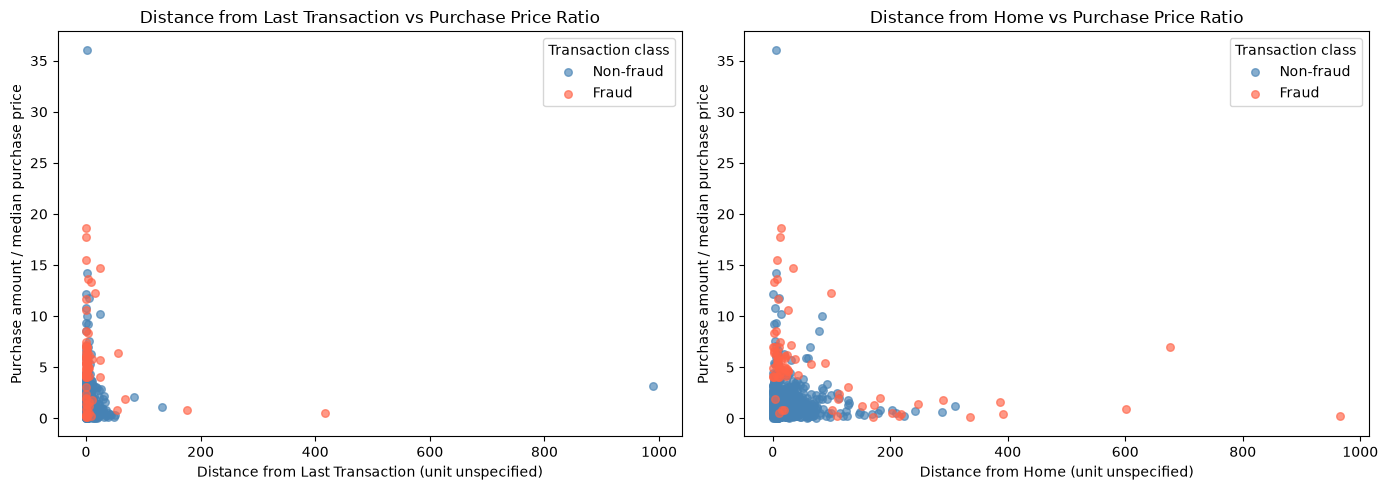

In [10]:
# Define distance columns and chart labels
distance_features = [
    ("distance_from_last_transaction", "Distance from Last Transaction"),
    ("distance_from_home", "Distance from Home")
]

# Use consistent colors for normal and fraudulent transactions
classes = [
    (0, "Non-fraud", "steelblue"),
    (1, "Fraud", "tomato")
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (column, label) in zip(axes, distance_features):
    plotted_count = 0

    for value, class_label, color in classes:
        # Select each class and plot its transactions directly
        group = df_clean.loc[df_clean["fraud"] == value]

        ax.scatter(
            group[column].to_numpy(),
            group["ratio_to_median_purchase_price"].to_numpy(),
            label=class_label,
            color=color,
            alpha=0.65,
            s=30
        )

        plotted_count += len(group)

    # Verify that all cleaned transactions are included
    print(f"{label}: {plotted_count} transactions plotted")

    ax.set_title(f"{label} vs Purchase Price Ratio")
    ax.set_xlabel(f"{label} (unit unspecified)")
    ax.set_ylabel("Purchase amount / median purchase price")
    ax.legend(title="Transaction class")

plt.tight_layout()
plt.show()

### Observations

Most transactions are concentrated at shorter distances and lower
purchase price ratios. Fraudulent transactions also appear at higher
ratios and longer distances, but the two classes overlap.

The transaction with the highest purchase price ratio is labeled
non-fraudulent. Therefore, an extreme value alone is not a reliable
fraud indicator.


## Conclusion

The original dataset contained 999 transactions. After removing
22 rows with missing values, 977 transactions remained, including
901 non-fraudulent and 76 fraudulent transactions. The fraud rate
in the cleaned dataset was approximately 7.78%.

Fraud rates differed across transaction groups. Transactions without
a PIN had a fraud rate of 8.84%, while no fraud was observed among
the 117 transactions using a PIN. Transactions using a chip had
a lower fraud rate (4.28%) than those without a chip (9.36%).
Online orders had a higher fraud rate (11.25%) than transactions
that were not online (0.63%).

The purchase price ratio and distance from home were right-skewed,
with most transactions concentrated at smaller values. Scatter plots
showed overlap between fraudulent and non-fraudulent transactions,
so distance and purchase price ratio alone did not clearly separate
the two classes.

These findings describe associations within the supplied dataset
and do not establish causation. No observed fraud in the PIN group
does not guarantee that PIN transactions are always safe. Removing
incomplete rows may also influence the results if those transactions
differ from the retained data. This analysis was limited to EDA;
no predictive model was trained or evaluated.
